In [1]:
print("hello")

hello


In [2]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve
)

train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

X_train = train.drop(columns="Class")
y_train = train["Class"]
X_test = test.drop(columns="Class")
y_test = test["Class"]

model = joblib.load("../models/model.joblib")
print("Modèle chargé :", type(model))

Modèle chargé : <class 'imblearn.pipeline.Pipeline'>


In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_proba = cross_val_predict(
    model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

In [4]:
COST_FALSE_NEGATIVE = 100   # coût d'une fraude ratée (montant moyen perdu, estimation)
COST_FALSE_POSITIVE = 5     # coût d'une fausse alerte (friction client, coût de vérification)

In [5]:
thresholds_to_test = np.arange(0.01, 1.0, 0.01)
costs = []

for t in thresholds_to_test:
    y_pred_t = (oof_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, y_pred_t).ravel()
    total_cost = COST_FALSE_NEGATIVE * fn + COST_FALSE_POSITIVE * fp
    costs.append(total_cost)

costs = np.array(costs)
best_idx = costs.argmin()
best_threshold = thresholds_to_test[best_idx]

print(f"Seuil optimal : {best_threshold:.2f}")
print(f"Coût total à ce seuil : {costs[best_idx]}")

Seuil optimal : 0.03
Coût total à ce seuil : 6420


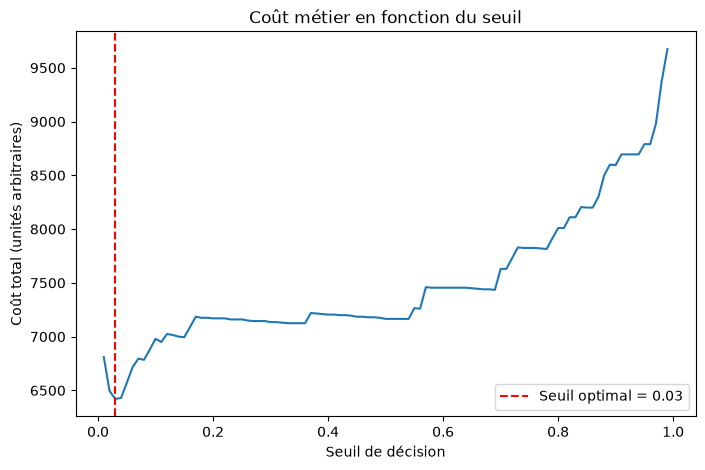

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds_to_test, costs)
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Seuil optimal = {best_threshold:.2f}")
plt.xlabel("Seuil de décision")
plt.ylabel("Coût total (unités arbitraires)")
plt.title("Coût métier en fonction du seuil")
plt.legend()
plt.show()

In [7]:
y_pred_default = (oof_proba >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_train, y_pred_default).ravel()
cost_default = COST_FALSE_NEGATIVE * fn + COST_FALSE_POSITIVE * fp

print(f"Coût au seuil 0.5      : {cost_default}")
print(f"Coût au seuil optimal  : {costs[best_idx]}")
print(f"Gain : {cost_default - costs[best_idx]} unités")

Coût au seuil 0.5      : 7165
Coût au seuil optimal  : 6420
Gain : 745 unités


In [8]:
import json

with open("../models/threshold.json", "w") as f:
    json.dump({
        "threshold": float(best_threshold),
        "cost_false_negative": COST_FALSE_NEGATIVE,
        "cost_false_positive": COST_FALSE_POSITIVE,
    }, f, indent=2)

print("Seuil sauvegardé.")

Seuil sauvegardé.


In [9]:
y_test_proba = model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= best_threshold).astype(int)

=== Matrice de confusion (test) ===
[[56831    33]
 [   12    86]]


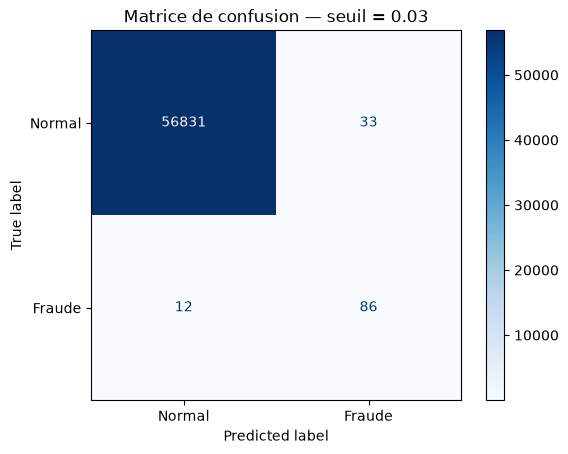


=== Classification report (test) ===
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
      Fraude       0.72      0.88      0.79        98

    accuracy                           1.00     56962
   macro avg       0.86      0.94      0.90     56962
weighted avg       1.00      1.00      1.00     56962


PR-AUC (test)  : 0.8792
ROC-AUC (test) : 0.9819


In [10]:
print("=== Matrice de confusion (test) ===")
cm = confusion_matrix(y_test, y_test_pred)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraude"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Matrice de confusion — seuil = {best_threshold:.2f}")
plt.show()

print("\n=== Classification report (test) ===")
print(classification_report(y_test, y_test_pred, target_names=["Normal", "Fraude"]))

pr_auc_test = average_precision_score(y_test, y_test_proba)
roc_auc_test = roc_auc_score(y_test, y_test_proba)
print(f"\nPR-AUC (test)  : {pr_auc_test:.4f}")
print(f"ROC-AUC (test) : {roc_auc_test:.4f}")

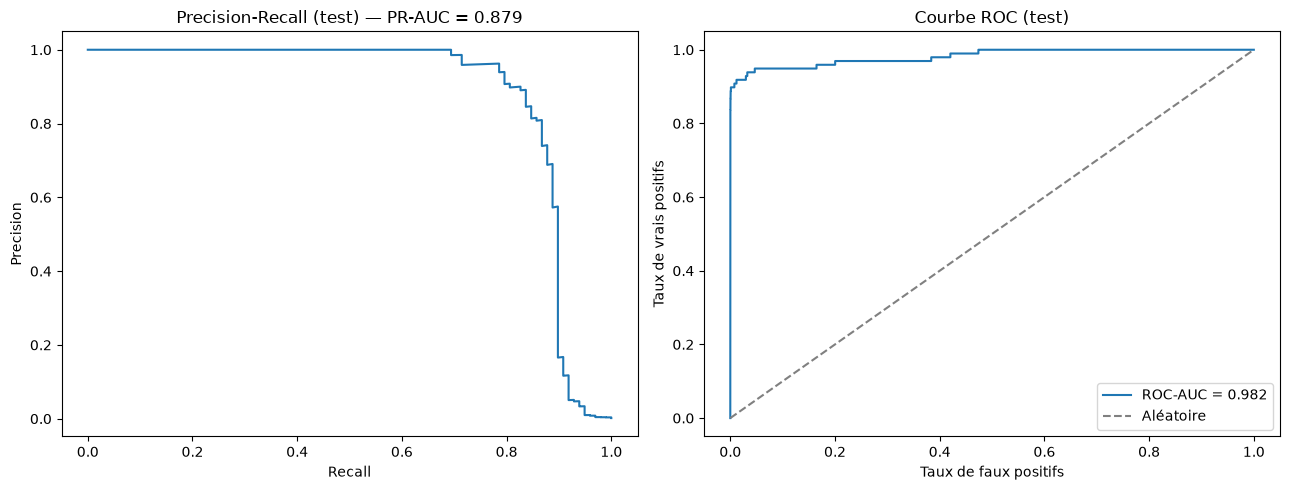

In [11]:
precision, recall, _ = precision_recall_curve(y_test, y_test_proba)
fpr, tpr, _ = roc_curve(y_test, y_test_proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(recall, precision)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title(f"Precision-Recall (test) — PR-AUC = {pr_auc_test:.3f}")

axes[1].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_test:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aléatoire")
axes[1].set_xlabel("Taux de faux positifs")
axes[1].set_ylabel("Taux de vrais positifs")
axes[1].set_title("Courbe ROC (test)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [12]:
tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()
final_cost = COST_FALSE_NEGATIVE * fn + COST_FALSE_POSITIVE * fp
print(f"Coût métier total sur le test set : {final_cost}")
print(f"Fraudes ratées (FN)  : {fn} / {y_test.sum()}")
print(f"Fausses alertes (FP) : {fp}")

Coût métier total sur le test set : 1365
Fraudes ratées (FN)  : 12 / 98
Fausses alertes (FP) : 33
